# 03 - LLM extraction

Two questions, answered in this order:

- **Part A, news understanding.** Does the LLM read a financial sentence correctly? Checked on the Financial PhraseBank,
  where people labelled the sentiment, so we know the right answer.
- **Part B, market signal.** Do the LLM's outputs predict next-day abnormal returns better than the baselines of notebook 02?

**Status of this notebook.** Everything that does not call the API runs offline: the prompt, the validation layer with
tests, the PhraseBank checks, FinBERT on PhraseBank, and the cost and time planning. The cells that call Groq are guarded
by `RUN_LLM` and need a `GROQ_API_KEY` (kept in the git-ignored `.env` file, see `.env.example`), so they are skipped until you turn them on. Nothing below is a result from the LLM
unless a cell says so.

In [1]:
import sys; sys.path.append('..')
import json, os, tempfile, types
from pathlib import Path
from unittest import mock

import httpx, groq
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

from src import llm_extract as llm
from src.baselines import finbert_probabilities
from src.evaluate import summarize_signal

SEED = 42
np.random.seed(SEED)
RAW, PROCESSED = Path('../data/raw'), Path('../data/processed')
pd.set_option('display.width', 200)

# ---- switches (the API cells are skipped unless RUN_LLM is True AND GROQ_API_KEY is set; the key lives in .env) ----
RUN_LLM = True           # flip to True only after setting GROQ_API_KEY. Every answer is cached on disk.
FEW_SHOT = False         # zero-shot first; True adds 4 worked examples (cached separately)
N_PHRASEBANK = 200       # sentences for the Part A check (stratified random subset of the 2,264)
PART_B = 'test'          # 'test' = the test-period rows of notebook 02, 'all' = all 30,000 rows
DEV_N = None             # e.g. 200: run Part B on a small random sample while debugging prompts
BATCH_SIZE = 10          # headlines per request (1 = one request per headline). Needed: the free tier allows only ~1,000 requests/day
CMP_N = 200              # sentences used to compare batched with single-item answers (single mode costs one request each)
TARGET_ROWS = 3000       # Part B: score at most this many rows, a fixed random subset (None = all). Free tier: ~200k tokens/day = ~1,400 rows/day
MAX_WAIT_MIN = 15        # sleep through rate-limit waits up to this long; a longer wait stops the run (re-run later, nothing is lost)
llm.MAX_WAIT_SECONDS = MAX_WAIT_MIN * 60
print('model:', llm.MODEL, '| prompt version:', llm.PROMPT_VERSION, '| cache folder:', llm.CACHE_DIR.resolve())

model: openai/gpt-oss-20b | prompt version: v1 | cache folder: D:\Sibankar Mandal\PROJECTS\FinSignal-LLM\FinSignal-LLM\data\llm_cache


## 1. What we ask the model, and why

For each headline the model returns four fields:

| field | meaning | used for |
|---|---|---|
| `sentiment` | positive / neutral / negative tone for shareholders | Part A (compared with human labels) |
| `score` | expected move relative to the market, from -1 to +1 | Part B (the signal that is correlated with returns) |
| `event_type` | earnings, guidance, m&a, analyst_rating, legal, product, macro, other | Part B ablations (does it work on some event types only?) |
| `confidence` | how clear the headline is, 0 to 1 | Part B (down-weight vague headlines) |

Design decisions, each with a reason:

- **JSON-only output.** Free text would need guessing to parse. JSON mode makes the structure machine-readable.
- **Temperature 0.** The model picks its most likely answer instead of sampling, so a re-run gives the same result.
  Reproducibility matters more than variety here.
- **The date is never sent.** Only ticker and headline. The model cannot see when the news happened, which removes one way
  for it to recall what the stock did afterwards. It can still recognise famous events from the text itself; that is the
  look-ahead (memorisation) risk, checked later by hiding company names.
- **Zero-shot first, few-shot second.** Zero-shot means the instructions alone; few-shot adds worked examples. The examples
  use invented companies so they cannot leak real outcomes. Both are cached under different keys.

In [2]:
print(llm.SYSTEM)
print('\n--- one few-shot example (invented company) ---')
t, h, a = llm.EXAMPLES[0]; print(t, '|', h, '->', a)

msgs = llm.build_messages('Acme raises guidance', 'ACME', few_shot=False)
text = json.dumps(msgs).lower()
assert 'date' not in llm.user_message('Acme raises guidance', 'ACME').lower(), 'the user message must not contain a date'
print('\nroles zero-shot:', [m['role'] for m in msgs], '| roles few-shot:', [m['role'] for m in llm.build_messages('x', 'T', True)])

You are a financial news analyst. You will be given one news headline and, if known, the stock ticker it is about.
Judge ONLY from the headline text. Return ONLY a JSON object with exactly these keys:
{"sentiment": "positive|neutral|negative",
 "score": <number from -1 to 1>,
 "event_type": "earnings|guidance|m&a|analyst_rating|legal|product|macro|other",
 "confidence": <number from 0 to 1>}
Definitions:
- sentiment: tone of the news for shareholders of that company.
- score: expected direction and size of the stock's move relative to the overall market over the next trading day,
  -1 = very negative, 0 = no information or no expected effect, +1 = very positive.
- event_type: the kind of event the headline reports; use "other" if none fits.
- confidence: how clear and informative the headline is, 0 = vague, 1 = unambiguous.

--- one few-shot example (invented company) ---
Zorvex | Zorvex raises full-year profit forecast after record quarterly revenue -> {'sentiment': 'positive', 'score

## 2. The validation layer, tested offline

The old scaffold turned any unparsable answer into a **neutral score of 0.0 and cached it forever**. That silently
converts model failures into "no signal" rows. The new code checks every answer:

$$
\text{valid} \iff \text{sentiment} \in \{\text{pos, neu, neg}\},\;
\text{event\_type} \in \text{allowed list},\;
-1 \le \text{score} \le 1,\;
0 \le \text{confidence} \le 1 .
$$

Invalid answers are returned as `ok = False`, **not cached**, and counted. Rate-limit errors are retried after the wait
the server asks for. Authentication errors and retired models are raised, because retrying cannot fix them.

These tests use a fake client that replays scripted replies, so they cost nothing and need no key. They test our
parsing and retry logic only. They do **not** prove the real API behaves this way.

In [3]:
cases = [  # (name, model reply, should it be accepted?)
    ('plain JSON',            '{"sentiment":"positive","score":0.4,"event_type":"earnings","confidence":0.8}', True),
    ('code fence',            '```json\n{"sentiment":"negative","score":-0.5,"event_type":"legal","confidence":0.9}\n```', True),
    ('text around the JSON',  'Sure! {"sentiment":"neutral","score":0,"event_type":"other","confidence":0.5} Hope that helps.', True),
    ('upper-case label',      '{"sentiment":"Positive","score":0.1,"event_type":"M&A","confidence":0.5}', True),
    ('invented label',        '{"sentiment":"bullish","score":0.4,"event_type":"earnings","confidence":0.8}', False),
    ('score out of range',    '{"sentiment":"positive","score":1.7,"event_type":"earnings","confidence":0.8}', False),
    ('confidence missing',    '{"sentiment":"positive","score":0.4,"event_type":"earnings"}', False),
    ('NaN score',             '{"sentiment":"positive","score":NaN,"event_type":"earnings","confidence":0.8}', False),
    ('not JSON at all',       'The headline looks positive.', False),
    ('empty reply',           '', False),
]
rows = []
for name, reply, should_pass in cases:
    try:
        llm.parse_response(reply); accepted = True
    except ValueError:
        accepted = False
    rows.append((name, should_pass, accepted, should_pass == accepted))
res = pd.DataFrame(rows, columns=['case', 'expected accept', 'accepted', 'ok'])
display(res)
assert res['ok'].all(), 'parse_response disagrees with the expected behaviour'
print('all', len(res), 'parsing cases behave as intended')

,case,expected accept,accepted,ok
0,plain JSON,True,True,True
1,code fence,True,True,True
2,text around the JSON,True,True,True
3,upper-case label,True,True,True
4,invented label,False,False,True
5,score out of range,False,False,True
6,confidence missing,False,False,True
7,NaN score,False,False,True
8,not JSON at all,False,False,True
9,empty reply,False,False,True


all 10 parsing cases behave as intended


In [4]:
class FakeClient:
    # Mimics client.chat.completions.create(...) and replays scripted replies (text, or an exception to raise).
    def __init__(self, replies):
        self.replies, self.calls, self.messages_seen = list(replies), 0, []
        self.chat = self.completions = self
    def create(self, **kwargs):
        self.calls += 1
        self.messages_seen.append(kwargs.get('messages'))
        reply = self.replies.pop(0)
        if isinstance(reply, Exception):
            raise reply
        return types.SimpleNamespace(choices=[types.SimpleNamespace(message=types.SimpleNamespace(content=reply))])

req = httpx.Request('POST', 'https://api.groq.com/test')
rate_limit = lambda wait: groq.RateLimitError('rate limited', response=httpx.Response(429, request=req, headers={'retry-after': str(wait)}), body=None)
bad_key = groq.AuthenticationError('bad key', response=httpx.Response(401, request=req), body=None)
GOOD = '{"sentiment":"positive","score":0.4,"event_type":"earnings","confidence":0.8}'
BAD = 'no json here'

REAL_CACHE = llm.CACHE_DIR
tmp = tempfile.TemporaryDirectory()
llm.CACHE_DIR = Path(tmp.name)                 # tests write to a throw-away folder, never to the real cache
llm.REQUESTS_PER_MINUTE = 10 ** 9              # switch pacing off for the tests

results = {}
with mock.patch.object(llm.time, 'sleep') as fake_sleep:
    c = FakeClient([GOOD]);                 r = llm.extract('h1', 'T', client=c); results['valid answer is returned'] = r['ok'] and c.calls == 1
    c2 = FakeClient([]);                    r = llm.extract('h1', 'T', client=c2); results['second call is a cache hit (no API call)'] = r['ok'] and c2.calls == 0
    c = FakeClient([BAD, BAD]);             r = llm.extract('h2', 'T', client=c);  results['two bad answers -> ok False, 2 calls'] = (not r['ok']) and c.calls == 2
    results['failure is NOT cached'] = not llm.cache_path('h2', 'T', False).exists()
    c = FakeClient([BAD, GOOD]);            r = llm.extract('h3', 'T', client=c);  results['bad then good -> accepted'] = r['ok'] and c.calls == 2
    fake_sleep.reset_mock()
    c = FakeClient([rate_limit(3), GOOD]);  r = llm.extract('h4', 'T', client=c);  results['rate limit is retried'] = r['ok'] and c.calls == 2
    results['waited the server-requested 3 s'] = (3.0,) in [call.args for call in fake_sleep.call_args_list]
    try:
        llm.extract('h5', 'T', client=FakeClient([bad_key])); raised = False
    except groq.AuthenticationError:
        raised = True
    results['authentication error is raised, not swallowed'] = raised
    results['cache key depends on few_shot'] = llm.cache_path('h', 'T', True) != llm.cache_path('h', 'T', False)
    results['cache key depends on ticker'] = llm.cache_path('h', 'A', False) != llm.cache_path('h', 'B', False)

display(pd.Series(results, name='passed').to_frame())
assert all(results.values()), 'a retry / cache test failed'
llm.CACHE_DIR = REAL_CACHE                    # point back at the real cache
llm.REQUESTS_PER_MINUTE = 20
tmp.cleanup()
llm.usage.update(requests=0, tokens=0)      # the fake calls above must not count as live usage
print('all', len(results), 'extract() behaviours pass (fake client only)')

,passed
valid answer is returned,True
second call is a cache hit (no API call),True
"two bad answers -> ok False, 2 calls",True
failure is NOT cached,True
bad then good -> accepted,True
rate limit is retried,True
waited the server-requested 3 s,True
"authentication error is raised, not swallowed",True
cache key depends on few_shot,True
cache key depends on ticker,True


all 10 extract() behaviours pass (fake client only)


### Batch mode, tested offline

`extract_batch()` sends several numbered headlines in one request and must match the answers back **by id, not by position**.
It also has to cope with a reply that skips an item, repeats an id, contains one invalid item, or is not usable at all,
without losing the good items and without caching the bad ones. Items that fail are re-sent once, grouped together.
The daily request cap is a special case: instead of sleeping for hours the run stops with `RateLimitExhausted`
(everything finished so far is already cached, so the run can simply be repeated later).

In [5]:
def breply(*entries, fence=False):    # entries: (id, sentiment, score)
    body = json.dumps({'results': [{'id': i, 'sentiment': sent, 'score': sc, 'event_type': 'earnings', 'confidence': 0.8} for i, sent, sc in entries]})
    return '```json\n' + body + '\n```' if fence else body

per_day = groq.RateLimitError('Rate limit reached ... on requests per day (RPD): Limit 1000, Used 1000', response=httpx.Response(429, request=req, headers={'retry-after': '6300'}), body=None)
long_wait = groq.RateLimitError('rate limited', response=httpx.Response(429, request=req, headers={'retry-after': '7000'}), body=None)

REAL_CACHE = llm.CACHE_DIR
tmp = tempfile.TemporaryDirectory(); llm.CACHE_DIR = Path(tmp.name)
llm.REQUESTS_PER_MINUTE = 10 ** 9; llm.TOKENS_PER_MINUTE = 10 ** 9
three = [('b1', 'T'), ('b2', 'T'), ('b3', 'T')]
t = {}
with mock.patch.object(llm.time, 'sleep'):
    c = FakeClient([breply((1, 'positive', 0.1), (2, 'negative', -0.2), (3, 'neutral', 0.0))])
    r = llm.extract_batch(three, client=c, batch_size=3)
    t['happy path: 3 items, 1 request, all valid'] = c.calls == 1 and all(x['ok'] for x in r)
    c = FakeClient([]); r = llm.extract_batch(three, client=c, batch_size=3)
    t['second run is fully cached (0 requests)'] = c.calls == 0 and all(x['ok'] for x in r)

    c = FakeClient([breply((3, 'neutral', 0.3), (1, 'positive', 0.1), (2, 'negative', -0.2))])
    r = llm.extract_batch([('o1', 'T'), ('o2', 'T'), ('o3', 'T')], client=c, batch_size=3)
    t['answers are matched by id, not by order'] = [x['score'] for x in r] == [0.1, -0.2, 0.3]

    c = FakeClient([breply((1, 'positive', 0.1), (3, 'neutral', 0.0)), breply((1, 'negative', -0.5))])
    r = llm.extract_batch([('m1', 'T'), ('m2', 'T'), ('m3', 'T')], client=c, batch_size=3)
    t['missing item is re-sent alone in a second request'] = c.calls == 2 and all(x['ok'] for x in r) and 'Score these 1 items' in c.messages_seen[1][1]['content'] and r[1]['score'] == -0.5

    c = FakeClient([breply((1, 'positive', 0.1), (2, 'negative', 1.7), (3, 'neutral', 0.0)), breply((1, 'negative', -0.4))])
    r = llm.extract_batch([('v1', 'T'), ('v2', 'T'), ('v3', 'T')], client=c, batch_size=3)
    t['invalid item (score 1.7) is repaired by the retry round'] = c.calls == 2 and all(x['ok'] for x in r)

    c = FakeClient([breply((1, 'positive', 0.1), (2, 'negative', 1.7)), breply((1, 'negative', 1.9))])
    r = llm.extract_batch([('f1', 'T'), ('f2', 'T')], client=c, batch_size=2)
    t['item that stays invalid -> ok False, the other stays ok'] = r[0]['ok'] and not r[1]['ok']
    t['failed item is NOT cached'] = not llm.cache_path('f2', 'T', False, 'batch').exists() and llm.cache_path('f1', 'T', False, 'batch').exists()

    c = FakeClient([breply((1, 'positive', 0.1), (1, 'negative', -0.1), (2, 'neutral', 0.0)), breply((1, 'positive', 0.2))])
    r = llm.extract_batch([('d1', 'T'), ('d2', 'T')], client=c, batch_size=2)
    t['duplicate id is rejected, then repaired'] = c.calls == 2 and all(x['ok'] for x in r) and r[0]['score'] == 0.2

    c = FakeClient([breply((1, 'positive', 0.1), (9, 'negative', -0.1), (2, 'neutral', 0.0))])
    r = llm.extract_batch([('x1', 'T'), ('x2', 'T')], client=c, batch_size=2)
    t['an id we never sent is ignored'] = c.calls == 1 and all(x['ok'] for x in r)

    c = FakeClient([breply((1, 'positive', 0.1), fence=True)])
    r = llm.extract_batch([('g1', 'T')], client=c, batch_size=1)
    t['reply wrapped in a code fence is accepted'] = r[0]['ok']

    c = FakeClient(['not json', 'still not json', 'nope', 'nope again'])
    r = llm.extract_batch([('u1', 'T'), ('u2', 'T')], client=c, batch_size=2)
    t['unusable replies -> all ok False (no crash)'] = not any(x['ok'] for x in r)

    r = llm.extract_batch([('n1', None)], client=FakeClient([breply((1, 'neutral', 0.0))]), batch_size=1)
    t['item without a ticker works'] = r[0]['ok']

    for label, err in [('daily limit message', per_day), ('long retry-after (7000 s)', long_wait)]:
        try:
            llm.extract_batch([('e' + label, 'T')], client=FakeClient([err]), batch_size=1); stopped = False
        except llm.RateLimitExhausted:
            stopped = True
        t[f'{label} -> RateLimitExhausted, no sleeping'] = stopped

t['batch cache key differs from single-mode key'] = llm.cache_path('h', 'T', False, 'batch') != llm.cache_path('h', 'T', False)
display(pd.Series(t, name='passed').to_frame())
assert all(t.values()), 'a batch test failed'
llm.CACHE_DIR = REAL_CACHE; llm.REQUESTS_PER_MINUTE = 20; llm.TOKENS_PER_MINUTE = 8000; tmp.cleanup()
llm.usage.update(requests=0, tokens=0)      # the fake calls above must not count as live usage
print('all', len(t), 'batch behaviours pass (fake client only)')

,passed
"happy path: 3 items, 1 request, all valid",True
second run is fully cached (0 requests),True
"answers are matched by id, not by order",True
missing item is re-sent alone in a second request,True
invalid item (score 1.7) is repaired by the retry round,True
"item that stays invalid -> ok False, the other stays ok",True
failed item is NOT cached,True
"duplicate id is rejected, then repaired",True
an id we never sent is ignored,True
reply wrapped in a code fence is accepted,True


all 15 batch behaviours pass (fake client only)


## 3. Part A data: Financial PhraseBank

**What it is.** About 4,800 English sentences from financial news about listed Finnish companies, each labelled
positive / neutral / negative by 5-8 finance-trained annotators (Malo et al., 2014, *Good debt or bad debt*,
JASIST 65(4), 782-796). We use the **AllAgree** file, where every annotator agreed (2,264 sentences), because those
labels are the least noisy. Licence: CC BY-NC-SA 3.0 (non-commercial, attribution required).

**Caveat about how different it is from our news.** PhraseBank sentences are fairly formal company statements
("operating profit rose to EUR 23.5 mn"), whereas our headlines are short, often about analyst ratings. Good PhraseBank
accuracy shows the model understands financial wording; it does not prove it will predict returns.

**Metrics.** With three classes $k$, from the confusion matrix we get precision, recall and F1 per class:

$$
P_k = \frac{TP_k}{TP_k + FP_k},\qquad R_k = \frac{TP_k}{TP_k + FN_k},\qquad F1_k = \frac{2\,P_k R_k}{P_k + R_k},
\qquad \text{macro-F1} = \frac{1}{3}\sum_{k} F1_k .
$$

Macro-F1 gives every class the same weight. That matters because the data is imbalanced (about 61% neutral): a model that
says "neutral" for everything gets 61% accuracy but a very low macro-F1.

In [6]:
pb_path = RAW / 'financial_phrasebank' / 'Sentences_AllAgree.txt'
lines = pb_path.read_bytes().decode('latin-1').splitlines()           # the file is latin-1, not utf-8
pb = pd.DataFrame([l.rsplit('@', 1) for l in lines], columns=['sentence', 'label'])

assert len(pb) == 2264, len(pb)
assert set(pb['label']) == {'positive', 'neutral', 'negative'}
assert pb['sentence'].str.len().gt(0).all(), 'empty sentence'
# a few real fragments exist (e.g. 'Welcome !', all labelled neutral); they are part of the benchmark, so they stay
print('sentences:', len(pb), '| shorter than 20 characters:', int((pb['sentence'].str.len() < 20).sum()))
dup = pb.duplicated('sentence', keep=False)
print('exact duplicate sentences:', int(pb.duplicated('sentence').sum()), '| duplicated sentences with conflicting labels:', int((pb[dup].groupby('sentence')['label'].nunique() > 1).sum()))
print('class shares:', pb['label'].value_counts(normalize=True).round(3).to_dict())
print('length in characters:', pb['sentence'].str.len().describe()[['mean', '50%', 'max']].round(0).to_dict())

LABELS = ['negative', 'neutral', 'positive']
maj = pb['label'].value_counts().idxmax()
print(f'\nmajority-class baseline: always "{maj}" -> accuracy {(pb["label"] == maj).mean():.3f}, '
      f'macro-F1 {f1_score(pb["label"], [maj] * len(pb), average="macro", labels=LABELS):.3f}')

# stratified subset used for the (paid / rate-limited) LLM calls
frac = N_PHRASEBANK / len(pb)
pb_sub = pb.groupby('label', group_keys=False).sample(frac=frac, random_state=SEED).sort_index()
print(f'subset for the LLM: {len(pb_sub)} sentences, class shares {pb_sub["label"].value_counts(normalize=True).round(3).to_dict()}')

sentences: 2264 | shorter than 20 characters: 5
exact duplicate sentences: 5 | duplicated sentences with conflicting labels: 0
class shares: {'neutral': 0.614, 'positive': 0.252, 'negative': 0.134}
length in characters: {'mean': 122.0, '50%': 111.0, 'max': 315.0}

majority-class baseline: always "neutral" -> accuracy 0.614, macro-F1 0.254
subset for the LLM: 200 sentences, class shares {'neutral': 0.615, 'positive': 0.25, 'negative': 0.135}


### FinBERT on the same sentences (for reference)

FinBERT outputs three probabilities; the predicted class is the largest one. **Important caveat:** FinBERT was fine-tuned on
the Financial PhraseBank (Araci, 2019), so on this data it is being tested on its own training domain and its numbers are
optimistic. The LLM sees these sentences without any training on them. Treat the FinBERT row as an upper-ish reference,
not as a fair head-to-head.

In [7]:
FB_CACHE = PROCESSED / 'finbert_phrasebank.csv'
if FB_CACHE.exists():
    fb = pd.read_csv(FB_CACHE)
else:
    fb = finbert_probabilities(pb['sentence'].tolist())
    fb.insert(0, 'sentence', pb['sentence'].values)
    fb.to_csv(FB_CACHE, index=False)
assert len(fb) == len(pb)
pb['finbert_label'] = fb[['negative', 'neutral', 'positive']].idxmax(axis=1).values

def classification_summary(y_true, y_pred):
    return {'accuracy': accuracy_score(y_true, y_pred), 'macro_f1': f1_score(y_true, y_pred, average='macro', labels=LABELS)}

def bootstrap_ci(y_true, y_pred, metric, n=1000, seed=SEED):
    # iid bootstrap over sentences (they are independent items, unlike stock-days), 95% interval
    rng = np.random.default_rng(seed); y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    vals = [metric(y_true[i], y_pred[i]) for i in (rng.integers(0, len(y_true), len(y_true)) for _ in range(n))]
    return np.percentile(vals, [2.5, 97.5])

full = classification_summary(pb['label'], pb['finbert_label'])
print(f'FinBERT on all {len(pb)} AllAgree sentences: accuracy {full["accuracy"]:.3f}, macro-F1 {full["macro_f1"]:.3f}  (in-domain, optimistic)')
display(pd.crosstab(pb['label'], pb['finbert_label']).reindex(index=LABELS, columns=LABELS))

FinBERT on all 2264 AllAgree sentences: accuracy 0.972, macro-F1 0.963  (in-domain, optimistic)


finbert_label,negative,neutral,positive
label,,,
negative,298,1,4
neutral,19,1345,27
positive,12,1,557


## 4. Planning the cost and time (no API calls)

The limits below were **measured** from the `x-ratelimit-*` headers of a live response (model `openai/gpt-oss-20b`, free tier,
2026-11-21), so they replace the guesses of an earlier version of this notebook. They belong to this model and account and can
change, so re-check them if you switch model.

| limit | measured value |
|---|---|
| requests per day (RPD) | 1,000 |
| tokens per minute (TPM) | 8,000 |

One request per headline would therefore need $N/1000$ days regardless of tokens. With $B$ headlines per request:

$$
\text{requests} = \lceil N/B \rceil, \qquad
T_{\text{request}} \approx T_{\text{system}} + B\,(T_{\text{headline}} + T_{\text{out}}),
$$

$$
\text{days} \approx \max\!\Big(\frac{\text{requests}}{\text{RPD}},\; \frac{\text{requests}\cdot T_{\text{request}}}{\text{TPM}\cdot 60 \cdot 24}\Big).
$$

Token counts use "about 3 characters per token", calibrated on one measured request (321 prompt tokens for about 885
characters), and $T_{\text{out}} = 55$ tokens per item (one measured single call produced 54 including 24 reasoning tokens).
Both are approximations; the live cells print the **actual** tokens per request afterwards so the table can be checked.

In [8]:
REQUESTS_PER_DAY, CHARS_PER_TOKEN, T_OUT_ITEM = 1_000, 3.0, 55
tok = lambda text: len(text) / CHARS_PER_TOKEN

ds = pd.read_csv(PROCESSED / 'dataset.csv', parse_dates=['entry_date'])
ds['row_id'] = ds.index
bs = pd.read_csv(PROCESSED / 'baseline_scores.csv')
ds = ds.merge(bs, on='row_id', how='left')
t_head = ds['headline'].str.len().mean() / CHARS_PER_TOKEN + 10      # average headline + ticker/framing tokens
T_SYS_SINGLE, T_SYS_BATCH = tok(llm.SYSTEM) + 20, tok(llm.BATCH_SYSTEM) + 20

scenarios = {'PhraseBank subset': N_PHRASEBANK,
             'Part B: test rows': int((ds['split'] == 'test').sum()),
             'Part B: all rows': len(ds)}
rows = []
for name, n in scenarios.items():
    for B in [1, 5, 10, 20]:
        requests = int(np.ceil(n / B))
        per_request = (T_SYS_SINGLE if B == 1 else T_SYS_BATCH) + B * (t_head + T_OUT_ITEM)
        days_rpd = requests / REQUESTS_PER_DAY
        days_tpm = requests * per_request / llm.TOKENS_PER_MINUTE / 60 / 24
        rows.append({'scenario': name, 'headlines/request': B, 'requests': requests, 'tokens/request': round(per_request),
                     'total tokens (M)': round(requests * per_request / 1e6, 2),
                     'days (request cap)': round(days_rpd, 2), 'days (token cap)': round(days_tpm, 2),
                     'days needed': round(max(days_rpd, days_tpm), 2)})
plan = pd.DataFrame(rows)
display(plan)
print(f'assumptions: {T_SYS_SINGLE:.0f} / {T_SYS_BATCH:.0f} system tokens (single / batch), {t_head:.0f} tokens per headline, {T_OUT_ITEM} output tokens per item')

,scenario,headlines/request,requests,tokens/request,total tokens (M),days (request cap),days (token cap),days needed
0,PhraseBank subset,1,200,398,0.08,0.20,0.01,0.20
1,PhraseBank subset,5,40,893,0.04,0.04,0.00,0.04
2,PhraseBank subset,10,20,1391,0.03,0.02,0.00,0.02
3,PhraseBank subset,20,10,2388,0.02,0.01,0.00,0.01
4,Part B: test rows,1,7542,398,3.00,7.54,0.26,7.54
5,Part B: test rows,5,1509,893,1.35,1.51,0.12,1.51
6,Part B: test rows,10,755,1391,1.05,0.76,0.09,0.76
7,Part B: test rows,20,378,2388,0.90,0.38,0.08,0.38
8,Part B: all rows,1,30000,398,11.94,30.00,1.04,30.00
9,Part B: all rows,5,6000,893,5.36,6.00,0.47,6.00


assumptions: 298 / 395 system tokens (single / batch), 45 tokens per headline, 55 output tokens per item


**Reading the table.** One headline per request makes the 7,542 test rows take about a week, and all 30,000 rows about a month.
At 10 per request the test rows fit in roughly a day and all rows in about three. Bigger batches save more requests but make
each answer depend more on its neighbours and a failed reply costs more, so the notebook compares batched with single answers
on the same sentences before trusting the batched scores.

## 5. Part A: run the LLM on PhraseBank (needs the API)

This section is skipped unless `RUN_LLM = True` and `GROQ_API_KEY` is set. It first checks that the configured model is
really served by Groq right now, because Groq retires models over time.

In [9]:
KEY_PRESENT = bool(os.environ.get('GROQ_API_KEY'))
CAN_RUN = RUN_LLM and KEY_PRESENT
print(f'RUN_LLM = {RUN_LLM} | GROQ_API_KEY present = {KEY_PRESENT}  ->  live calls {"ENABLED" if CAN_RUN else "SKIPPED"}')

if CAN_RUN:
    served = sorted(m.id for m in llm.get_client().models.list().data)
    print('models served right now:', served)
    assert llm.MODEL in served, f'{llm.MODEL!r} is not served; set the GROQ_MODEL environment variable to one of the ids above'

RUN_LLM = True | GROQ_API_KEY present = True  ->  live calls ENABLED


models served right now: ['allam-2-7b', 'canopylabs/orpheus-arabic-saudi', 'canopylabs/orpheus-v1-english', 'meta-llama/llama-prompt-guard-2-22m', 'meta-llama/llama-prompt-guard-2-86m', 'openai/gpt-oss-120b', 'openai/gpt-oss-20b', 'openai/gpt-oss-safeguard-20b', 'qwen/qwen3.8-27b', 'whisper-large-v3', 'whisper-large-v3-turbo']


In [10]:
def run_extract(df, text_col, ticker_col=None, few_shot=False, batch_size=None, max_rows=None):
    # Score every row of df; returns a DataFrame indexed like df. Stops cleanly if the daily limit is reached.
    # Rows are shuffled first (fixed seed) so a batch mixes tickers and days instead of one day's neighbours.
    # Everything already answered is cached, so running the cell again continues where it stopped.
    batch_size = BATCH_SIZE if batch_size is None else batch_size
    order = df.sample(frac=1, random_state=SEED).index
    if max_rows: order = order[:max_rows]                    # a fixed random subset; the same rows every time
    items = [(df.at[i, text_col], df.at[i, ticker_col] if ticker_col else None) for i in order]
    done = {}
    try:
        if batch_size > 1:
            assert not few_shot, 'few-shot is not implemented for batch mode'
            for start in range(0, len(items), 100):          # 100 items per step so progress is printed
                answers = llm.extract_batch(items[start:start + 100], batch_size=batch_size)
                done.update(zip(order[start:start + 100], answers))
                print(f'{min(start + 100, len(items))}/{len(items)}', end='  ', flush=True)
        else:
            for n, (idx, (text, ticker)) in enumerate(zip(order, items), 1):
                done[idx] = llm.extract(text, ticker, few_shot=few_shot)
                if n % 50 == 0: print(f'{n}/{len(items)}', end='  ', flush=True)
    except llm.RateLimitExhausted as err:
        print(f'\nSTOPPED EARLY: {err}. Answers already received are cached: run this cell again later to continue.')
    out = pd.DataFrame.from_dict(done, orient='index').reindex(df.index)
    if 'ok' not in out:                                    # stopped before a single answer arrived
        out['ok'] = False
    out['ok'] = out['ok'].fillna(False).astype(bool)
    out['error'] = out['error'].fillna('') if 'error' in out else ''
    out.loc[~out['ok'] & (out['error'] == ''), 'error'] = 'not run yet (stopped early)'
    out.loc[~out.index.isin(order), 'error'] = 'outside the target sample'
    print(f'\nlive usage this session: {llm.usage["requests"]} requests, {llm.usage["tokens"]:,} tokens'
          + (f' ({llm.usage["tokens"] / llm.usage["requests"]:.0f} per request)' if llm.usage["requests"] else ''))
    return out

MODE = 'batch' if BATCH_SIZE > 1 else 'single'
PB_OUT = PROCESSED / f'llm_phrasebank_{"fewshot" if FEW_SHOT else "zeroshot"}{"_batch" if BATCH_SIZE > 1 else ""}.csv'
llm_pb = None
if CAN_RUN:
    llm_pb = run_extract(pb_sub, 'sentence', few_shot=FEW_SHOT)
    llm_pb.to_csv(PB_OUT)
elif PB_OUT.exists():
    llm_pb = pd.read_csv(PB_OUT, index_col=0)
    print('loaded earlier results from', PB_OUT)
else:
    print('Part A skipped: no earlier results and live calls are disabled.')

100/200  

200/200  


live usage this session: 0 requests, 0 tokens


### Part A results

Computed only if results exist. Failed answers (invalid JSON etc.) are reported separately; the metrics use valid answers.

valid answers: 200 / 200  (failure rate 0.0%)


,accuracy,macro_f1
LLM (this model),0.935,0.936
"FinBERT (in-domain, same sentences)",0.975,0.960
Majority class,0.615,0.254


LLM accuracy 95% CI [0.900, 0.970] | macro-F1 95% CI [0.901, 0.967]


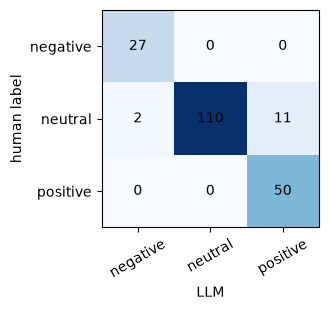

sentiment and score point in opposite directions in 0.0% of valid answers


In [11]:
if llm_pb is None:
    print('no LLM results yet, nothing to evaluate')
else:
    ok = llm_pb['ok'].astype(bool)
    print(f'valid answers: {ok.sum()} / {len(llm_pb)}  (failure rate {1 - ok.mean():.1%})')
    if (~ok).any(): print('failure reasons:', llm_pb.loc[~ok, 'error'].value_counts().to_dict())

    good = llm_pb[ok].join(pb_sub[['label']])
    y_true, y_pred = good['label'], good['sentiment']
    sub_fb = pb.loc[good.index, 'finbert_label']

    table = pd.DataFrame({
        'LLM (this model)': classification_summary(y_true, y_pred),
        'FinBERT (in-domain, same sentences)': classification_summary(y_true, sub_fb),
        'Majority class': classification_summary(y_true, [maj] * len(y_true)),
    }).T
    ci_acc = bootstrap_ci(y_true, y_pred, accuracy_score)
    ci_f1 = bootstrap_ci(y_true, y_pred, lambda a, b: f1_score(a, b, average='macro', labels=LABELS))
    display(table.round(3))
    print(f'LLM accuracy 95% CI [{ci_acc[0]:.3f}, {ci_acc[1]:.3f}] | macro-F1 95% CI [{ci_f1[0]:.3f}, {ci_f1[1]:.3f}]')

    cm = confusion_matrix(y_true, y_pred, labels=LABELS)
    fig, ax = plt.subplots(figsize=(3.6, 3.2)); ax.imshow(cm, cmap='Blues')
    ax.set_xticks(range(3)); ax.set_xticklabels(LABELS, rotation=30); ax.set_yticks(range(3)); ax.set_yticklabels(LABELS)
    for i in range(3):
        for j in range(3): ax.text(j, i, cm[i, j], ha='center', va='center')
    ax.set_xlabel('LLM'); ax.set_ylabel('human label'); plt.tight_layout(); plt.show()

    # consistency: does the numeric score agree in sign with the sentiment label?
    clash = ((good['sentiment'] == 'positive') & (good['score'] < 0)) | ((good['sentiment'] == 'negative') & (good['score'] > 0))
    print(f'sentiment and score point in opposite directions in {clash.mean():.1%} of valid answers')

### Does batching change the answers?

Batching saves requests, but the model now sees several items at once. If batched answers differ systematically from
single-item answers, the saving would be paying for noise. On the same sentences we compare the two modes:
agreement of the sentiment label, accuracy against the human labels, and how closely the numeric scores track each other
(Spearman rank correlation $\rho$ between the two score vectors). Single mode costs one request per sentence, so only the
first `CMP_N` sentences are used.

In [12]:
if CAN_RUN and BATCH_SIZE > 1:
    cmp_rows = pb_sub.head(CMP_N)
    single = run_extract(cmp_rows, 'sentence', batch_size=1)
    batched = run_extract(cmp_rows, 'sentence', batch_size=BATCH_SIZE)
    both = single.add_suffix('_single').join(batched.add_suffix('_batch')).join(cmp_rows[['label']])
    both = both[both['ok_single'] & both['ok_batch']]
    agree = (both['sentiment_single'] == both['sentiment_batch']).mean()
    rho = both[['score_single', 'score_batch']].corr(method='spearman').iloc[0, 1]
    print(f'\nsentences compared: {len(both)} | same sentiment label: {agree:.1%} | score rank correlation: {rho:.3f} '
          f'| mean |score difference|: {(both["score_single"] - both["score_batch"]).abs().mean():.3f}')
    display(pd.DataFrame({'single': classification_summary(both['label'], both['sentiment_single']),
                          f'batched x{BATCH_SIZE}': classification_summary(both['label'], both['sentiment_batch'])}).T.round(3))
else:
    print('skipped: needs live calls and BATCH_SIZE > 1')

50/200  

100/200  

150/200  

200/200  


live usage this session: 0 requests, 0 tokens
100/200  

200/200  


live usage this session: 0 requests, 0 tokens

sentences compared: 200 | same sentiment label: 90.0% | score rank correlation: 0.870 | mean |score difference|: 0.070


,accuracy,macro_f1
single,0.905,0.896
batched x10,0.935,0.936


## 6. Part B: scores for our headlines (needs the API)

Same guard as Part A. Rows come from `PART_B` ('test' = the test period of notebook 02, so the TF-IDF baseline can be
compared fairly; the other baselines are untrained and work on any rows). Each headline is sent with its ticker only.

In [13]:
rows_b = ds[ds['split'] == 'test'] if PART_B == 'test' else ds
if DEV_N: rows_b = rows_b.sample(DEV_N, random_state=SEED)
print(f'Part B rows: {len(rows_b):,} ({PART_B}{", dev sample" if DEV_N else ""}) | days: {rows_b["entry_date"].nunique()}')

B_OUT = PROCESSED / f'llm_scores_{PART_B}{"_dev" if DEV_N else ""}_{"fewshot" if FEW_SHOT else "zeroshot"}{"_batch" if BATCH_SIZE > 1 else ""}.csv'
llm_b = None
if CAN_RUN:
    llm_b = rows_b[['row_id']].join(run_extract(rows_b, 'headline', 'ticker', few_shot=FEW_SHOT, max_rows=TARGET_ROWS))
    llm_b.to_csv(B_OUT, index=False)
elif B_OUT.exists():
    llm_b = pd.read_csv(B_OUT)
    print('loaded earlier results from', B_OUT)
else:
    print('Part B skipped: no earlier results and live calls are disabled.')

Part B rows: 7,542 (test) | days: 107
100/3000  

200/3000

300/3000  

400/3000

500/3000  

600/3000

... (21 outputs left out)

2800/3000  

2900/3000  

3000/3000  


live usage this session: 179 requests, 255,592 tokens (1428 per request)


In [14]:
if llm_b is None:
    print('no LLM scores yet, nothing to compare')
else:
    ok = llm_b['ok'].astype(bool)
    err = llm_b['error'].fillna('')
    pending, outside = err.eq('not run yet (stopped early)'), err.eq('outside the target sample')
    print(f'valid answers: {ok.sum():,} | not run yet: {pending.sum():,} | outside the target sample: {outside.sum():,} | real failures: {(~ok & ~pending & ~outside).sum():,}')
    scored = rows_b.merge(llm_b[ok][['row_id', 'sentiment', 'score', 'event_type', 'confidence']].rename(columns={'score': 'llm_score'}), on='row_id')
    scored['llm_score_x_conf'] = scored['llm_score'] * scored['confidence']

    print('event types:', scored['event_type'].value_counts(normalize=True).round(3).to_dict())
    print('share of exactly neutral scores (0):', round((scored['llm_score'] == 0).mean(), 3))

    cols = {'LLM score': 'llm_score', 'LLM score x confidence': 'llm_score_x_conf', 'FinBERT': 'finbert', 'Lexicon': 'lexicon'}
    if scored['tfidf_lr'].notna().all(): cols['TF-IDF + LR'] = 'tfidf_lr'
    cmp_ = pd.DataFrame({k: summarize_signal(scored, v) for k, v in cols.items()}).T
    display(cmp_[['coverage', 'accuracy', 'acc_lo', 'acc_hi', 'mean_daily_ic', 'ic_lo', 'ic_hi', 'ic_t', 'n_days']].astype(float).round(4))
    print('Interpretation rule: a signal is only distinguishable from noise if its mean_daily_ic interval excludes 0.')

valid answers: 3,000 | not run yet: 0 | outside the target sample: 4,542 | real failures: 0
event types: {'other': 0.38, 'macro': 0.196, 'analyst_rating': 0.19, 'product': 0.085, 'earnings': 0.085, 'guidance': 0.025, 'legal': 0.024, 'm&a': 0.016}
share of exactly neutral scores (0): 0.285


,coverage,accuracy,acc_lo,acc_hi,mean_daily_ic,ic_lo,ic_hi,ic_t,n_days
LLM score,0.7150,0.4895,0.4620,0.5187,0.0233,-0.0258,0.0759,0.8867,105.0
LLM score x confidence,0.7150,0.4895,0.4620,0.5187,0.0238,-0.0257,0.0770,0.9041,105.0
FinBERT,1.0000,0.4900,0.4674,0.5117,0.0138,-0.0301,0.0583,0.5966,105.0
Lexicon,0.3647,0.5055,0.4712,0.5403,0.0200,-0.0224,0.0641,0.9162,104.0
TF-IDF + LR,1.0000,0.5093,0.4832,0.5355,-0.0179,-0.0635,0.0295,-0.7112,105.0


Interpretation rule: a signal is only distinguishable from noise if its mean_daily_ic interval excludes 0.


## 7. Status and next steps

In [15]:
print('offline parts run: prompt, validation tests, PhraseBank checks, FinBERT on PhraseBank, cost/time plan')
print('Part A (LLM on PhraseBank):', 'done' if llm_pb is not None else 'NOT RUN yet')
print('Part B (LLM on our headlines):', 'done' if llm_b is not None else 'NOT RUN yet')
if not CAN_RUN and llm_pb is None:
    print('\nTo run the LLM cells: put GROQ_API_KEY in the .env file in the project root, set RUN_LLM = True, start with a small N_PHRASEBANK and DEV_N.')

offline parts run: prompt, validation tests, PhraseBank checks, FinBERT on PhraseBank, cost/time plan
Part A (LLM on PhraseBank): done
Part B (LLM on our headlines): done
